# Demo 1 — Crop Recommendation with Classic Machine Learning

**FarmWise, Session 1 · Africa Digital Skills Conference**

In this demo we build a model that recommends a crop from a farm's soil and
weather numbers:

| input | meaning |
|-------|---------|
| N, P, K | nitrogen, phosphorus, potassium in the soil |
| temperature | °C |
| humidity | % |
| ph | soil acidity |
| rainfall | mm |

We will: **explore the data → train a model → evaluate it → predict → save it.**

> We build each step *by hand* first so you can see what happens, then show the
> same step wrapped in the reusable `farmwise` package (what Session 2 will use).

### Setup
Make the `farmwise` package importable and turn on inline plots.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # project root, so `import farmwise` works

import pandas as pd
import matplotlib.pyplot as plt

from farmwise import config
print("Dataset path:", config.CROP_DATASET_PATH)

Dataset path: /Users/macbookpro/Projects/ads/farmwise-workshop/data/raw/Crop_recommendation.csv


## Step 1 — Load the data

The dataset is a CSV. Let's read it with pandas and look at the first few rows.

In [2]:
df = pd.read_csv(config.CROP_DATASET_PATH)
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


How big is it, and what are the columns?

In [3]:
print("rows, columns:", df.shape)
print("columns:", list(df.columns))

rows, columns: (2200, 8)
columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


## Step 2 — Explore: is the data balanced?

A model learns best when each crop has enough examples. Let's count rows per crop.

In [4]:
counts = df["label"].value_counts()
counts

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

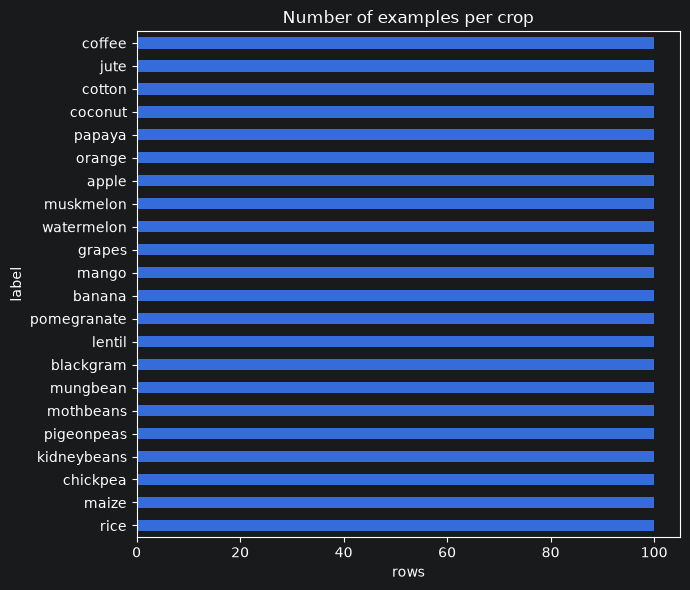

In [5]:
counts.sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Number of examples per crop")
plt.xlabel("rows")
plt.tight_layout()
plt.show()

The classes look evenly sized — good. Now a quick look at the feature numbers
(their typical ranges matter a lot for Demo 3).

In [6]:
df.describe().round(1)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.0,2200.0,2200.0,2200.0,2200.0,2200.0,2200.0
mean,50.6,53.4,48.1,25.6,71.5,6.5,103.5
std,36.9,33.0,50.6,5.1,22.3,0.8,55.0
min,0.0,5.0,5.0,8.8,14.3,3.5,20.2
25%,21.0,28.0,20.0,22.8,60.3,6.0,64.6
50%,37.0,51.0,32.0,25.6,80.5,6.4,94.9
75%,84.2,68.0,49.0,28.6,89.9,6.9,124.3
max,140.0,145.0,205.0,43.7,100.0,9.9,298.6


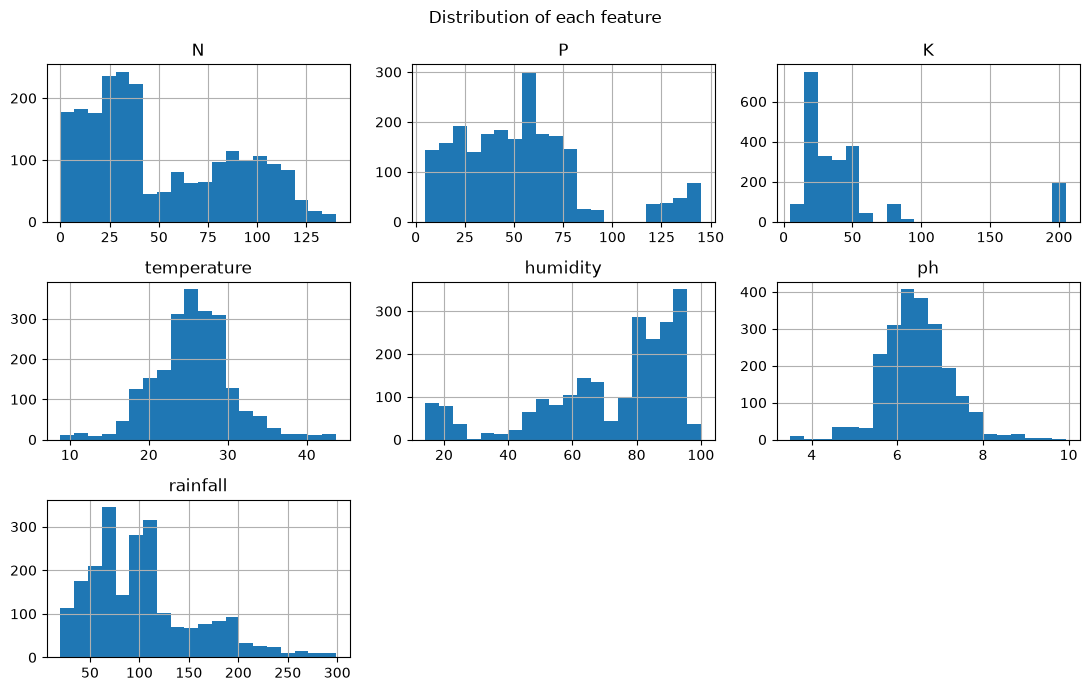

In [7]:
df[["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]].hist(
    figsize=(11, 7), bins=20
)
plt.suptitle("Distribution of each feature")
plt.tight_layout()
plt.show()

### The packaged way
`farmwise.ml.data.load_crop_dataset()` does the same read **plus validation**
(checks the columns exist, drops bad rows). This is what the app will call.

In [8]:
from farmwise.ml.data import load_crop_dataset, class_balance, FEATURE_COLUMNS

df = load_crop_dataset()
print("loaded & validated:", df.shape)
print("features:", FEATURE_COLUMNS)

loaded & validated: (2200, 8)
features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


## Step 3 — Split into training and test sets

We train on one part of the data and keep the rest *unseen* to check the model
honestly. `stratify=y` keeps every crop represented in both parts.

In [9]:
from sklearn.model_selection import train_test_split

X = df[FEATURE_COLUMNS]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("train rows:", len(X_train), "| test rows:", len(X_test))

train rows: 1760 | test rows: 440


## Step 4 — Train a model (Random Forest)

A Random Forest is a collection of decision trees that vote. It's a strong,
no-fuss choice for tabular data like this.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_acc = accuracy_score(y_test, rf.predict(X_test))
print(f"Random Forest test accuracy: {rf_acc:.3f}")

Random Forest test accuracy: 0.995


### Is the extra complexity worth it? Compare to a simple baseline
Logistic Regression is a much simpler model. If the forest isn't clearly better,
prefer the simple one.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)
base_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Logistic Regression baseline: {base_acc:.3f}")
print(f"Random Forest:                {rf_acc:.3f}")

Logistic Regression baseline: 0.973
Random Forest:                0.995


### The packaged way
`farmwise.ml.train.train_crop_model()` does the split, trains the forest **and**
the baseline, and returns everything we need to evaluate — plus metadata.

In [12]:
from farmwise.ml.train import train_crop_model

result = train_crop_model(df)
print("accuracy :", round(result.accuracy, 3))
print("baseline :", round(result.baseline_accuracy, 3))

accuracy : 0.995
baseline : 0.973


## Step 5 — Evaluate properly

Accuracy alone can hide problems. The **classification report** shows precision
and recall per crop.

In [13]:
print(result.report_text)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

A **confusion matrix** shows which crops get mixed up (off-diagonal cells).

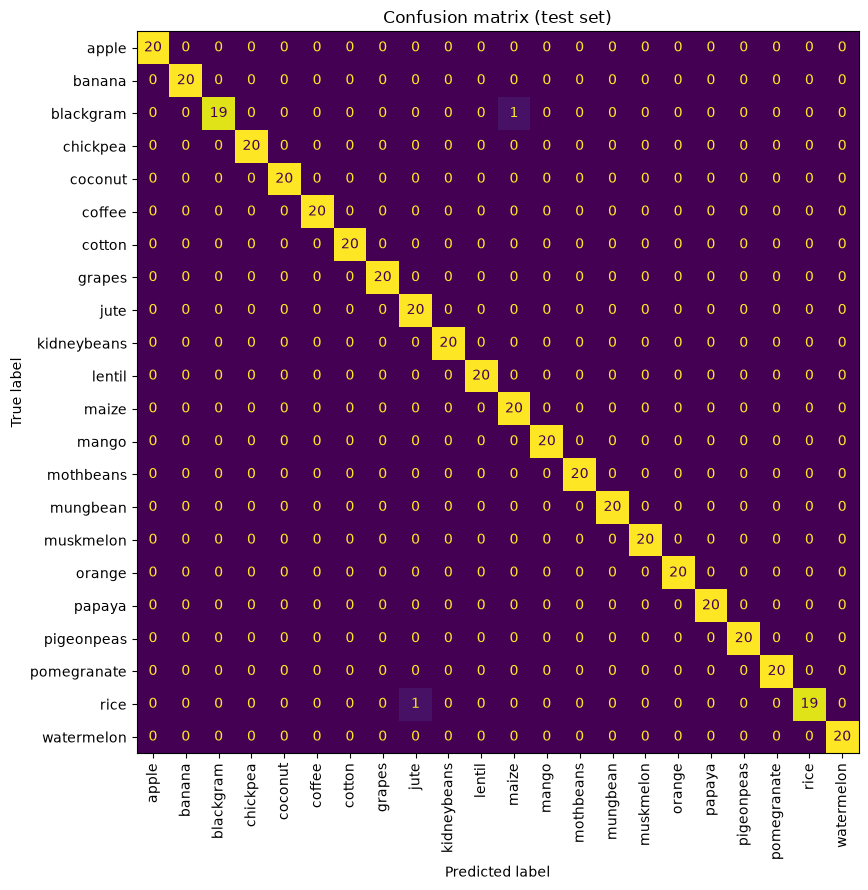

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(
    confusion_matrix=result.confusion, display_labels=result.classes
).plot(ax=ax, xticks_rotation="vertical", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

## Step 6 — Which inputs matter most?

Feature importance tells us what the forest leaned on.

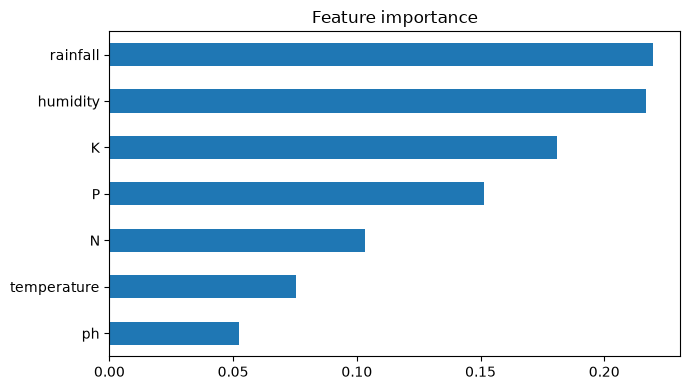

rainfall       0.220
humidity       0.217
K              0.181
P              0.151
N              0.103
temperature    0.075
ph             0.052
dtype: float64

In [15]:
imp = pd.Series(result.feature_importance).sort_values()
imp.plot(kind="barh", figsize=(7, 4))
plt.title("Feature importance")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(3)

## Step 7 — Save the model + metadata

We save the trained model and a JSON file describing it (features, classes,
accuracy, training date, **and where the data came from**).

In [16]:
from farmwise.ml.train import save_model
import json

model_path, metadata_path = save_model(result)
print("saved model    ->", model_path)
print("saved metadata ->", metadata_path)

meta = json.loads(metadata_path.read_text())
{k: meta[k] for k in ["model_type", "accuracy", "n_classes", "training_date", "dataset_source"]}

saved model    -> /Users/macbookpro/Projects/ads/farmwise-workshop/models/crop_model.joblib
saved metadata -> /Users/macbookpro/Projects/ads/farmwise-workshop/models/crop_model_metadata.json


{'model_type': 'RandomForestClassifier',
 'accuracy': 0.9954545454545455,
 'n_classes': 22,
 'training_date': '2026-11-02T14:59:19+00:00',
 'dataset_source': "Kaggle 'Crop Recommendation' dataset (Atharva Ingle). Collection location and methodology are undocumented; widely understood to reflect Indian agronomic conditions — NOT validated for Ghana."}

## Step 8 — Predict for a sample farm

`predict_crop` is a plain, typed function — exactly what Session 2's API will call.
It returns the top crop, its confidence, and the top-3 candidates.

In [17]:
from farmwise.ml.predict import predict_crop, CropFeatures

sample = CropFeatures(N=90, P=42, K=43, temperature=21, humidity=82, ph=6.5, rainfall=200)
pred = predict_crop(sample)

print("Recommended crop:", pred.crop)
print("Confidence      :", round(pred.confidence, 3))
print("Top 3           :", [(s.crop, round(s.probability, 3)) for s in pred.top3])
print("Out of range?   :", pred.out_of_distribution)

Recommended crop: rice
Confidence      : 0.915
Top 3           : [('rice', 0.915), ('jute', 0.085), ('apple', 0.0)]
Out of range?   : False


## Recap

- Loaded and explored the crop dataset.
- Trained a Random Forest (and checked it beats a simple baseline).
- Evaluated with a report, confusion matrix, and feature importance.
- Saved the model + metadata, and made a typed prediction.

**Next:** in Demo 2 we build the RAG farming assistant. In Demo 3 we ask the hard
question — *this data wasn't collected in Ghana, so can we trust it here?*